# LL, RR, and LR efficiency versus ΔR only

Use the LPC kernel. This notebook reads `drEff_cont.coffea` once and produces **one figure**, with no heatmaps or intermediate count plots. It keeps the same signal points, cut, and regular pT/vxy ranges as the previous notebook. LR includes electron L and positron R only.

The points are binned efficiencies at numerical ΔR midpoints. Horizontal bars show bin widths, and vertical bars show unweighted binomial efficiency uncertainties. Lines only guide the eye. Empty denominator bins remain gaps. The last save cell is optional.


In [7]:
from pathlib import Path
import gc
import re
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from hist.intervals import ratio_uncertainty

LPC_REPO = Path('/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe')
f_sig = LPC_REPO / 'python_analysis/coffea/VertexRes2026/drEff_cont.coffea'
cut = 'cut0'

samples = {10: {0.2: [100]}, 20: {0.2: [100]}, 30: {0.2: [100]}, 40: {0.2: [100]}, 50: {0.2: [100]}, 60: {0.1: [100], 0.2: [100]}, 70: {0.1: [100], 0.2: [100]}, 80: {0.1: [100], 0.2: [100]}, 90: {0.1: [100], 0.2: [100]}, 100: {0.2: [100]}}

expected_dr_edges = np.asarray([
    0, 0.01, 0.02, 0.04, 0.06, 0.08, 0.1,
    0.15, 0.2, 0.3, 0.4, 0.5, 0.7, 1, 1.5, 2, 3, 4, 5,
])
print('Input:', f_sig)
print('Samples:', samples)


Input: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/VertexRes2026/drEff_cont.coffea
Samples: {10: {0.2: [100]}, 20: {0.2: [100]}, 30: {0.2: [100]}, 40: {0.2: [100]}, 50: {0.2: [100]}, 60: {0.1: [100], 0.2: [100]}, 70: {0.1: [100], 0.2: [100]}, 80: {0.1: [100], 0.2: [100]}, 90: {0.1: [100], 0.2: [100]}, 100: {0.2: [100]}}


In [2]:
# Keep only the four required histograms after loading the file.
print('Loading coffea output...', flush=True)
loaded_output = util.load(str(f_sig))
sig_histo = loaded_output[0]
category_names = ('LL', 'RR', 'LR')
histograms = {
    suffix: sig_histo[f'genvtx_pt_vxy_dr_{suffix}']
    for suffix in ('den',) + category_names
}
del sig_histo, loaded_output
gc.collect()
print('Loaded. Retained only the four required histograms.', flush=True)


Loading coffea output...
Loaded. Retained only the four required histograms.


In [3]:
# Select signal points using the same filename convention as plotTools.signalPoint.
# No plotTools import or 2D plotting is needed.
available_samples = list(histograms['den'].axes['samp'])
parsed_samples = []
for name in available_samples:
    match = re.search(r'Mchi-(\d+p\d+)_dMchi-(\d+p\d+)_ctau-(\d+)', name)
    if match is None:
        continue
    mchi = float(match.group(1).replace('p', '.'))
    dmchi = float(match.group(2).replace('p', '.'))
    lifetime = float(match.group(3))
    mass1 = mchi - dmchi / 2
    parsed_samples.append((name, mass1, dmchi / mass1, lifetime))

selected_names = []
for m1, deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            matches = [
                name for name, mass1, splitting, lifetime in parsed_samples
                if np.isclose(mass1, m1, rtol=1e-8, atol=1e-8)
                and np.isclose(splitting, delta, rtol=1e-8, atol=1e-8)
                and lifetime == ctau
            ]
            if len(matches) != 1:
                raise ValueError(f'Expected one sample for {(m1, delta, ctau)}, found {matches}')
            if matches[0] in selected_names:
                raise ValueError(f'Duplicate sample: {matches[0]}')
            selected_names.append(matches[0])
if not selected_names:
    raise ValueError('No signal points selected.')
print('Selected samples:')
for name in selected_names:
    print(' ', name)

# Sum the 3D count array over pT and vxy, keeping all ΔR bins in one step.
counts_vs_dr = {}
reference_edges = None
for suffix, histogram in histograms.items():
    summed = np.zeros(len(expected_dr_edges) - 1, dtype=float)
    for name in selected_names:
        selected = histogram[{'samp': name, 'cut': cut}]
        names = tuple(axis.name for axis in selected.axes)
        expected_names = (f'pt_{suffix}', f'vxy_{suffix}', f'dr_{suffix}')
        if names != expected_names:
            raise ValueError(f'Unexpected axis order for {suffix}: {names}')
        current_edges = tuple(np.asarray(axis.edges).copy() for axis in selected.axes)
        if reference_edges is None:
            reference_edges = current_edges
        else:
            for expected, actual in zip(reference_edges, current_edges):
                np.testing.assert_array_equal(expected, actual)
        np.testing.assert_allclose(current_edges[2], expected_dr_edges, rtol=0, atol=1e-12)
        summed += selected.values(flow=False).sum(axis=(0, 1))
    counts_vs_dr[suffix] = summed

pt_edges, vxy_edges, dr_edges = reference_edges
print(f'Included pT: [{pt_edges[0]:g}, {pt_edges[-1]:g}) GeV')
print(f'Included vxy: [{vxy_edges[0]:g}, {vxy_edges[-1]:g}) cm')
print('Underflow and overflow excluded.')
# Release histogram objects now that only small 1D count arrays are needed.
del histograms, histogram, selected
gc.collect()


Selected samples:
  sig_2022_Mchi-11p0_dMchi-2p0_ctau-100
  sig_2022_Mchi-22p0_dMchi-4p0_ctau-100
  sig_2022_Mchi-33p0_dMchi-6p0_ctau-100
  sig_2022_Mchi-44p0_dMchi-8p0_ctau-100
  sig_2022_Mchi-55p0_dMchi-10p0_ctau-100
  sig_2022_Mchi-63p0_dMchi-6p0_ctau-100
  sig_2022_Mchi-66p0_dMchi-12p0_ctau-100
  sig_2022_Mchi-73p5_dMchi-7p0_ctau-100
  sig_2022_Mchi-77p0_dMchi-14p0_ctau-100
  sig_2022_Mchi-84p0_dMchi-8p0_ctau-100
  sig_2022_Mchi-88p0_dMchi-16p0_ctau-100
  sig_2022_Mchi-94p5_dMchi-9p0_ctau-100
  sig_2022_Mchi-99p0_dMchi-18p0_ctau-100
  sig_2022_Mchi-110p0_dMchi-20p0_ctau-100
Included pT: [0, 100) GeV
Included vxy: [0, 20) cm
Underflow and overflow excluded.


0

In [4]:
denominator = counts_vs_dr['den']
if not np.all(np.isfinite(denominator)) or np.any(denominator < 0):
    raise ValueError('Invalid denominator counts.')
if not np.allclose(denominator, np.round(denominator)):
    raise ValueError('This uncertainty calculation assumes unit-weight event counts.')
valid = denominator > 0
curves = {}
for category in category_names:
    numerator = counts_vs_dr[category]
    if not np.all(np.isfinite(numerator)) or np.any(numerator < 0) or np.any(numerator > denominator):
        raise ValueError(f'Invalid {category} numerator counts.')
    if not np.allclose(numerator, np.round(numerator)):
        raise ValueError('This uncertainty calculation assumes unit-weight event counts.')
    efficiency = np.divide(numerator, denominator,
                           out=np.full_like(numerator, np.nan), where=valid)
    uncertainty = np.full((2, len(denominator)), np.nan)
    if np.any(valid):
        uncertainty[:, valid] = ratio_uncertainty(numerator[valid], denominator[valid], 'efficiency')
    curves[category] = {'efficiency': efficiency, 'uncertainty': uncertainty}
    print(f'\n{category}: bin interval, numerator / denominator, efficiency')
    for i, (low, high) in enumerate(zip(dr_edges[:-1], dr_edges[1:])):
        if valid[i]:
            print(f'  [{low:g}, {high:g}): {numerator[i]:g} / {denominator[i]:g} '
                  f'= {100 * efficiency[i]:.3f}% '
                  f'(-{100 * uncertainty[0,i]:.3f}, +{100 * uncertainty[1,i]:.3f} percentage points)')
        else:
            print(f'  [{low:g}, {high:g}): denominator 0, omitted')
if np.any(sum(counts_vs_dr[c] for c in category_names) > denominator):
    raise ValueError('LL + RR + LR counts exceed the common denominator.')



LL: bin interval, numerator / denominator, efficiency
  [0, 0.01): 135 / 2174 = 6.210% (-0.520, +0.562 percentage points)
  [0.01, 0.02): 626 / 6483 = 9.656% (-0.368, +0.381 percentage points)
  [0.02, 0.04): 3217 / 26263 = 12.249% (-0.203, +0.206 percentage points)
  [0.04, 0.06): 5552 / 43396 = 12.794% (-0.161, +0.162 percentage points)
  [0.06, 0.08): 7207 / 59399 = 12.133% (-0.134, +0.135 percentage points)
  [0.08, 0.1): 8858 / 74334 = 11.916% (-0.119, +0.120 percentage points)
  [0.1, 0.15): 26624 / 239063 = 11.137% (-0.064, +0.065 percentage points)
  [0.15, 0.2): 31415 / 301664 = 10.414% (-0.056, +0.056 percentage points)
  [0.2, 0.3): 64993 / 725956 = 8.953% (-0.034, +0.034 percentage points)
  [0.3, 0.4): 43063 / 816796 = 5.272% (-0.025, +0.025 percentage points)
  [0.4, 0.5): 36233 / 840531 = 4.311% (-0.022, +0.022 percentage points)
  [0.5, 0.7): 57980 / 1.61538e+06 = 3.589% (-0.015, +0.015 percentage points)
  [0.7, 1): 55721 / 2.04174e+06 = 2.729% (-0.011, +0.011 percent

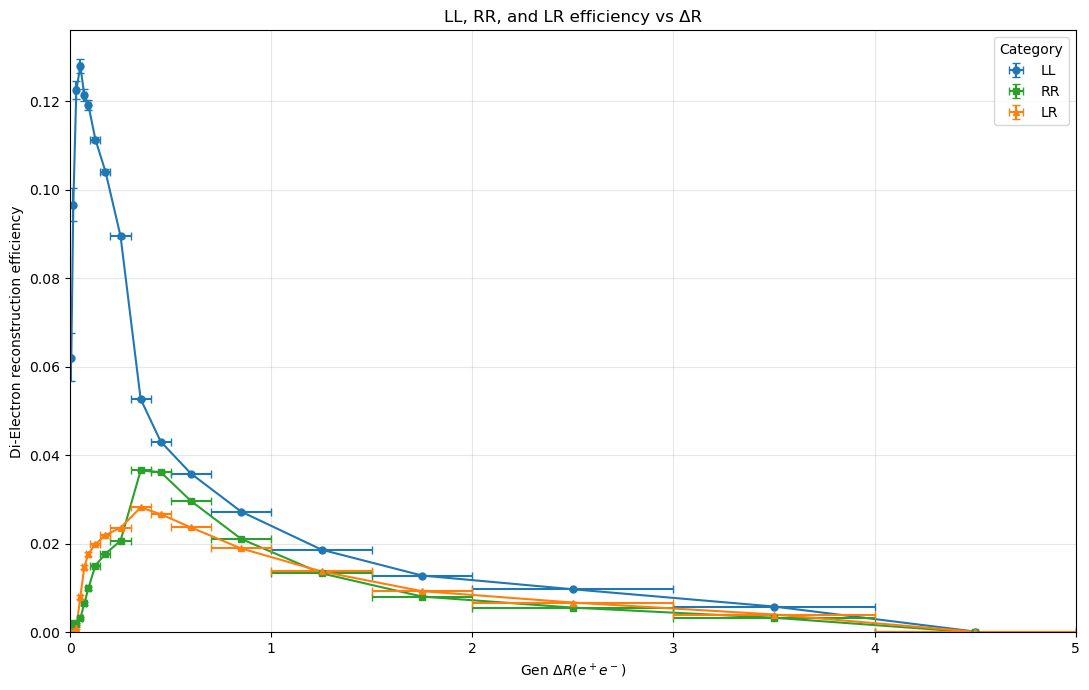

In [8]:
x = (dr_edges[:-1] + dr_edges[1:]) / 2
xerr = np.vstack((x - dr_edges[:-1], dr_edges[1:] - x))
colours = {'LL': 'tab:blue', 'RR': 'tab:green', 'LR': 'tab:orange'}
markers = {'LL': 'o', 'RR': 's', 'LR': '^'}

fig, ax = plt.subplots(figsize=(11, 7))
for category in category_names:
    efficiency = curves[category]['efficiency']
    uncertainty = curves[category]['uncertainty']
    finite = np.isfinite(efficiency)
    ax.plot(x, efficiency, color=colours[category], linewidth=1.5)
    ax.errorbar(x[finite], efficiency[finite],
                xerr=xerr[:,finite], yerr=uncertainty[:,finite],
                fmt=markers[category], color=colours[category],
                markersize=5, capsize=3, label=category)
ax.set_xlim(dr_edges[0], dr_edges[-1])
# Optional small-ΔR view: replace the line above with ax.set_xlim(0, 0.2).
ax.set_ylim(bottom=0)
ax.set_xlabel(r'Gen $\Delta R(e^+e^-)$')
ax.set_ylabel('Di-Electron reconstruction efficiency')
ax.set_title('LL, RR, and LR efficiency vs ΔR')
ax.grid(alpha=0.3)
ax.legend(title='Category')
fig.tight_layout()
plt.show()


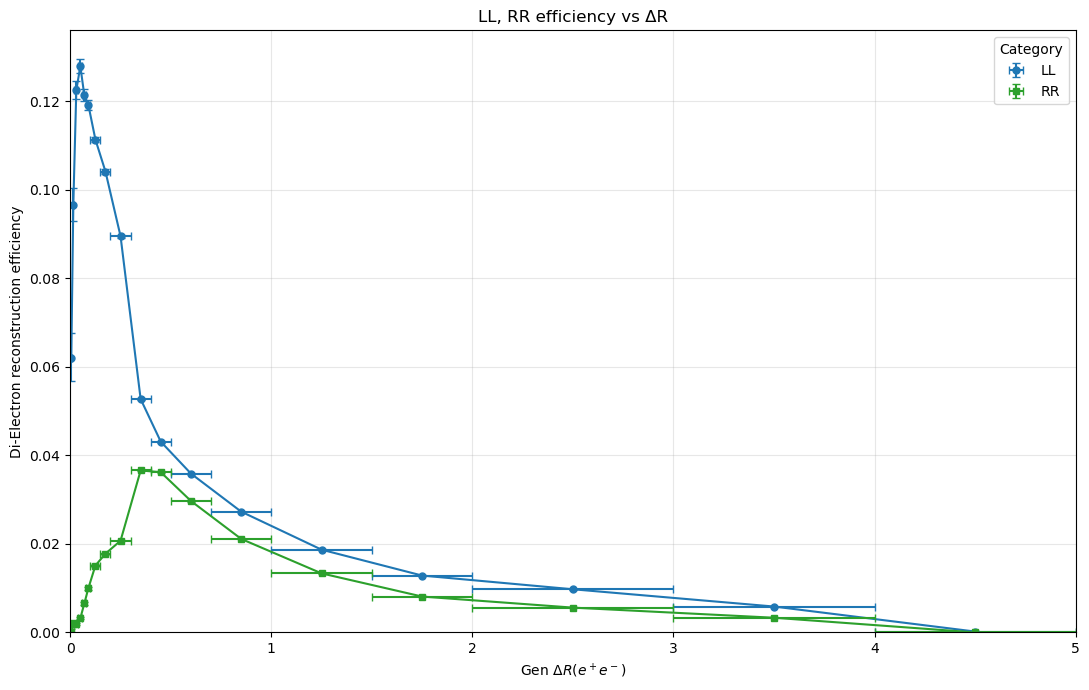

In [11]:
x = (dr_edges[:-1] + dr_edges[1:]) / 2
xerr = np.vstack((x - dr_edges[:-1], dr_edges[1:] - x))

colours = {'LL': 'tab:blue', 'RR': 'tab:green'}
markers = {'LL': 'o', 'RR': 's'}

fig, ax = plt.subplots(figsize=(11, 7))

for category in ('LL', 'RR'):
    efficiency = curves[category]['efficiency']
    uncertainty = curves[category]['uncertainty']
    finite = np.isfinite(efficiency)

    ax.plot(
        x, efficiency,
        color=colours[category],
        linewidth=1.5,
    )

    ax.errorbar(
        x[finite],
        efficiency[finite],
        xerr=xerr[:, finite],
        yerr=uncertainty[:, finite],
        fmt=markers[category],
        color=colours[category],
        markersize=5,
        capsize=3,
        label=category,
    )

ax.set_xlim(dr_edges[0], dr_edges[-1])
# Optional small-ΔR view: use ax.set_xlim(0, 0.2).
ax.set_ylim(bottom=0)
ax.set_xlabel(r'Gen $\Delta R(e^+e^-)$')
ax.set_ylabel('Di-Electron reconstruction efficiency')
ax.set_title('LL, RR efficiency vs ΔR')
ax.grid(alpha=0.3)
ax.legend(title='Category')

fig.tight_layout()
plt.show()

## Optional: save the one figure
Only run the following cell if you want to create PNG and PDF files on LPC. It makes a new folder each time and saves the figure above without redrawing it.


In [6]:
from datetime import datetime
output_parent = LPC_REPO / 'python_analysis/plots/VertexRecEff_vs_dR_curve_only'
output_parent.mkdir(parents=True, exist_ok=True)
output_dir = output_parent / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
output_dir.mkdir(exist_ok=False)
for extension in ('png', 'pdf'):
    destination = output_dir / f'LL_RR_LR_efficiency_vs_dR.{extension}'
    with destination.open('xb') as stream:
        fig.savefig(stream, format=extension, dpi=300, bbox_inches='tight', facecolor='white')
    print('Saved:', destination)


Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_dR_curve_only/20261015_105348_264244/LL_RR_LR_efficiency_vs_dR.png
Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_dR_curve_only/20261015_105348_264244/LL_RR_LR_efficiency_vs_dR.pdf
